# Практическая работа №1: Основы анализа и моделирования социальных сетей

Выполнила студентка гр. 4385 Касимова Варвара Андреевна. Вариант №4.

## Цель работы

Овладеть навыками работы с математическими пакетами для моделирования, визуализации и анализа социальных сетей.

## Основные теоретические положения

- Пятичисловая сводка
  - Размер сети - количество акторов
  - Плотность сети - доля связей в сети от максимально возможного числа связей
  $$
  den(G) = \frac{\sum_{i} \sum_{j} x_{ij}}{g(g -1)} = \frac{l}{C^2_g}
  $$
  - Компонента связности - подгруппа, все акторы которой связаны прямо или ковенно
  - Диаметр сети - максимальное растояние между двумя узлами в сети
  $$
  diam(G) = max_{n_i, n_j \in N} d(n_i, n_j)
  $$
  - Коэффициент кластеризации (глобальный) - мера, которая характеризует степень треугольности всей сети
  $$
  cl_t(G) = \frac{3T_{\Delta}(G)}{T_3(G)}
  $$
  где $T_{\Delta}(G)$ - число триад с 3 связями,

    $T_3(G)$ - число триад с 2 или 3 связями
- Меры центральности (количсетвенная мера $C_A$, определяющая относительню важность актора или его влияение на основе его позиции и связи с другими акторами)
  - Нормированная центральность по степени
  $$
  C'_D (n_i) = \frac{deg(n_i)}{g-1}
  $$
  - Нормированная центральность по близости
  $$
  C'_C (n_i) = \frac{g-1}{\sum_{j=1}^g d(n_i, n_j)}
  $$
  - Нормированная центральность по посредничеству
  $$
  C'_B (n_i) = \frac{C_B(n_i)}{C^2_{g-1}}\\
  C_B(n_i) = \sum_{j<k} \frac{σ_{jk}(n_i)}{σ_{jk}}
  $$
  где $σ_{jk}$ - количество кратчайших путей из n_j в n_k,

    $σ_{jk}(n_i)$ - количество кратчайших путей из n_j в n_k, проходящих через n_i
  - Нормированная центральность по информации
  $$
  C'_I (n_i) = \frac{C_I(n_i)}{\sum_{i=1}^g C_I(n_i)}\\
  C_I(n_i) = \frac{1}{c_{ii} + \frac{T-2R}{g}}\\
  $$
  $A = \mathbb{1} + K$ - матрица псевдосмежности,

    $K$ - матрица Кирхгофа,

    $C = A ^{-1}$, $T = tr(C)$, $R = \sum_{j=1}^g c_{ij}$
- Меры престижа (количетвенная мера $P_A$ влиятельности актора, онованная на входящих связях)
  - Нормированный престиж по степени
  $$
  P'_D(n_i) = \frac{deg_{in}(n_i)}{g-1}
  $$
  - престиж по близости
  $$
  P_P(n_i) = \frac{|I_i|/(g-1)}{\sum_{n_j \in I_i} d(n_j, n_i)/|I_i|}
  $$
  $I_i$ - множество акторов, достижимых в $n_i$
  - престиж по рангу
  $$
  P'_R(n_i) = \frac{P_R(n_i)}{\sum_{k=1}^{g-1} a^k ⋅ A_{g-1}^k}\\
  P_R(n_i) = x_{1i} ⋅ P_R(n_1) + x_{2i} ⋅ P_R(n_2) + ... + x_{gi} ⋅ P_R(n_g)
  $$
  $a$ - параметр затухания

## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей вычислить описательные характеристики. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

1. Из файла florentine_marital.csv извлечь социоматрицу с помощью соответствующих функций. Вывести полученную социоматрицу на экран.




In [14]:
# установим и подкючим библиотеку для работы с графами
install.packages("igraph")
library(igraph)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
# читаем данные из файла, данные разделены запятыми, для обозначения комментариев используется #,
# передаем эти символы как параметры, чтобы функция правильно считала данные
data <- read.csv("florentine_marital.csv", sep = ",", comment.char = "#")
# преобразуем считанные данные в матрицу
mat <- as.matrix(data)
# временно уберем названия столбцов, чтобы вернуть их в п.3, а сейчас вывести только числа
names <- colnames(mat)
colnames(mat) <- NULL
mat

0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,1
0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,1
0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0


2. Преобразовать социоматрицу в список рёбер. Вывести первые 5 элементов списка рёбер.

In [5]:
# для построения графа из матрицы смежности есть специальная функция.
# параметры - матрица смежности и флаг, что граф ненаправленный, чтобы связи учитывались только 1 раз
# другие параметры (веса, названия строк и столбцов, диагональность) в данном случае необязательны
graf <- graph_from_adjacency_matrix(mat, mode = "undirected")
# функция E() возвращает список ребер графа, выведем первые 5
E(graf)[1:5]

+ 5/20 edges from 8f22321 (vertex names):
[1] Acciaiuoli--Medici     Albizzi   --Ginori     Albizzi   --Guadagni  
[4] Albizzi   --Medici     Barbadori --Castellani

3. Присвоить имена столбцам и строкам социоматрицы (имена — первая строка в csv-файле после комментариев).


In [4]:
# вернем названия столбцам и строкам
# если еще раз запустить код п.2, то в спике ребер будут фамилии, а не индексы
rownames(mat) <- names
colnames(mat) <- names
mat

,Acciaiuoli,Albizzi,Barbadori,Bischeri,Castellani,Ginori,Guadagni,Lamberteschi,Medici,Pazzi,Peruzzi,Pucci,Ridolfi,Salviati,Strozzi,Tornabuoni
Acciaiuoli,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
Albizzi,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
Barbadori,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
Bischeri,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
Castellani,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0
Ginori,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Guadagni,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,1
Lamberteschi,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
Medici,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,1
Pazzi,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


4. С помощью соответствующих функций по полученной социоматрице построить ненаправленную сеть. Объяснить параметры, передаваемые в функцию.


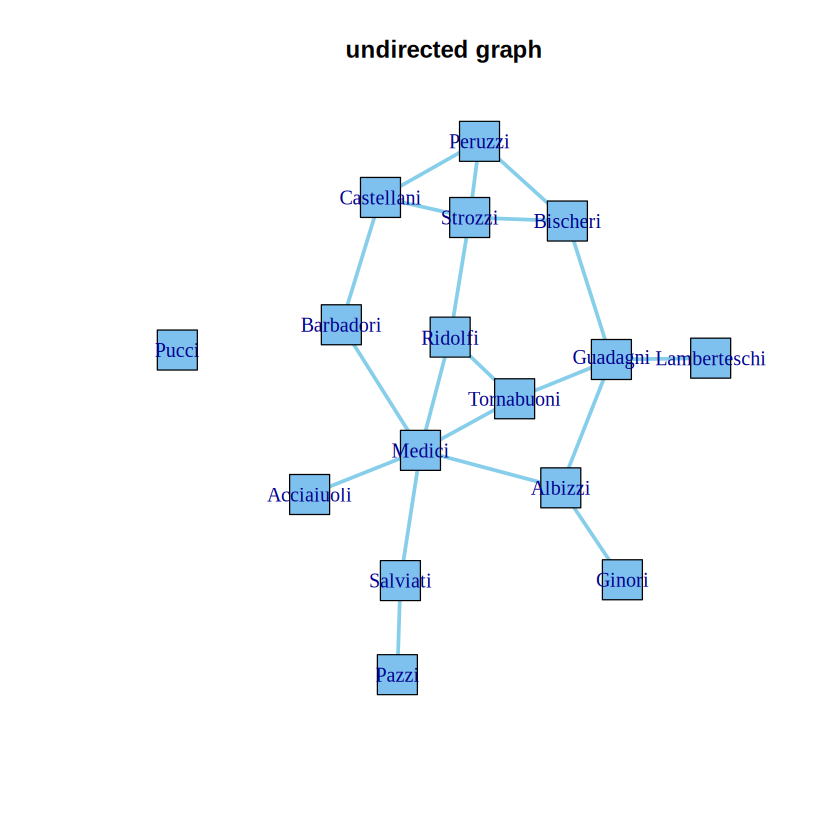

In [54]:
# просто строим ненаправленный граф
plot(
  graf,                        # граф, которй строим
  main = "undirected graph",   # название полученного изображения графа
  vertex.color = "SkyBlue2", vertex.shape = "square",   # параметры вершин (некоторые)
  edge.color = "SkyBlue", edge.width = 3,               # параметры ребер (некоторые)
  layout = layout_nicely       # укладка (значение по умолчанию такое, выбирает оптимальный алгоритм в зависимости от графа)
)


5. Отобразить сеть с помощью алгоритмов укладки Фрюхтермана—Рейнгольда и Камада—Каваи. Объяснить, в чём различие между алгоритмами и укладками.


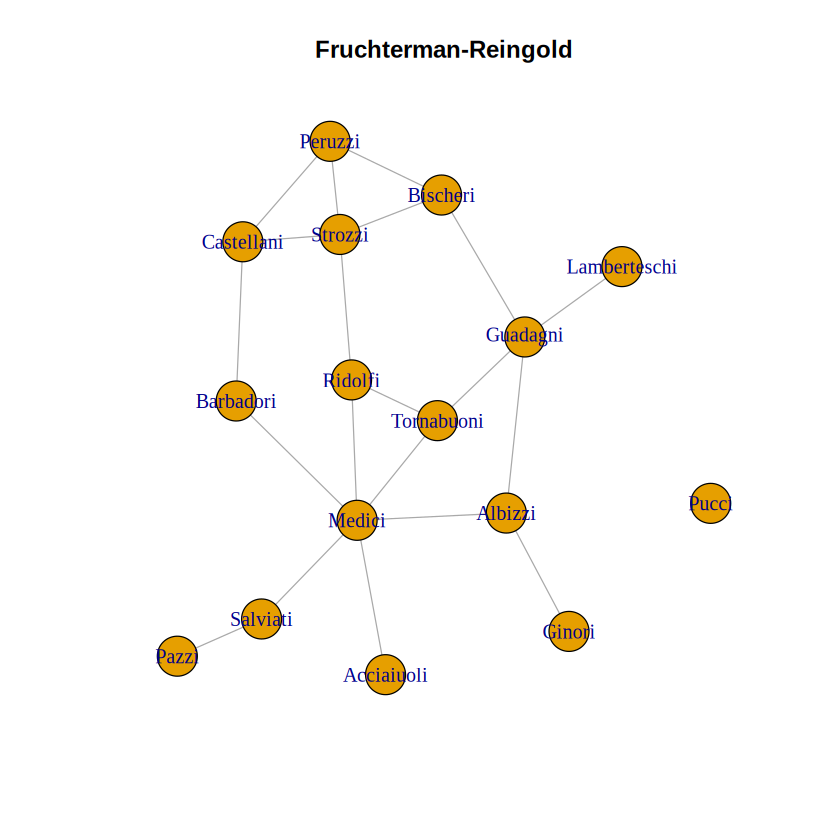

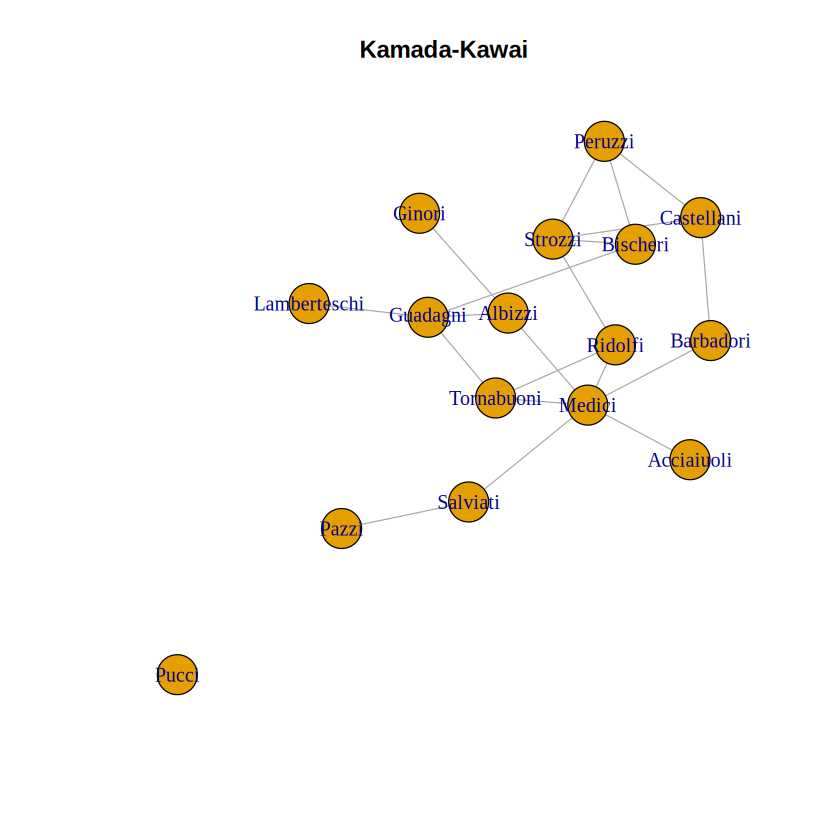

In [11]:
# укажем, какую укладку использовать для изображения графа, остальное не буду указывать
plot(graf, layout = layout_with_fr, main = "Fruchterman-Reingold")
plot(graf, layout = layout_with_kk, main = "Kamada-Kawai")

Алгоритмы укладки Фрюхтермана—Рейнгольда и Камада—Каваи относятся к силовым алгоритмам укладки графа, основанных на уменьшении общей энергии сети.

В алгоритме Фрюхтермана—Рейнгольда задаются силы притяжения $F_a = \frac{d^2}{k}$ и отталкивания $F_r = \frac{-k^2}{d}$, где $k = \sqrt{\frac{L ⋅ W}{g}}$ - коэффициент, а также начальная температура. На каждой итерации для каждой вершины вычисляются силы, точка перемещается в сторону уменьшения равнодействующей и ее температура уменьшается. Итерации повторяются, пока все точки не замерзнут.

Алгоритм Камада—Каваи для построеня укладки решает систему дифференциальных ураавнений в частных производных, тоже на каждой итерации уменьшает общую энергию системы за счет сдвига узла с самым большим вкладом.

В итоге получилось, что при укладке с использованием алгортима Фрюхтермана—Рейнгольда ребра не пересекаются, в отличие от укладки алгоритмом Камада—Каваи. Такой граф нагляднее и его легче анализировать.

6. Вывести «описательную сводку» сети.

In [18]:
# граф ненаправленный, с именованными вершинами (которых 16),
# невзвешенный и недвудольный, также выведены все 20 ребер
# функция summary() возвращает только первые 2 строчки
graf

IGRAPH 8f22321 UN-- 16 20 -- 
+ attr: name (v/c)
+ edges from 8f22321 (vertex names):
 [1] Acciaiuoli--Medici       Albizzi   --Ginori       Albizzi   --Guadagni    
 [4] Albizzi   --Medici       Barbadori --Castellani   Barbadori --Medici      
 [7] Bischeri  --Guadagni     Bischeri  --Peruzzi      Bischeri  --Strozzi     
[10] Castellani--Peruzzi      Castellani--Strozzi      Guadagni  --Lamberteschi
[13] Guadagni  --Tornabuoni   Medici    --Ridolfi      Medici    --Salviati    
[16] Medici    --Tornabuoni   Pazzi     --Salviati     Peruzzi   --Strozzi     
[19] Ridolfi   --Strozzi      Ridolfi   --Tornabuoni  


7. Вычислить «пятичисловую сводку» сети:
* (a). Вычислить размер сети.
* (b). Вычислить плотность сети вручную и с помощью соответствующей функции. Сделать выводы.
* (c). Определить число компонент в сети по графику. Подтвердить свои догадки с помощью соответствующей функции. Сделать выводы.
* (d). Вычислить диаметр сети. Сделать выводы
* (e). Вычислить коэффициент кластеризации. Сделать выводы.


a. Так как матрица смежности размера $16\times16$, то размер сети $$g = 16$$

b. Плотность сети вычисляется по формуле:
$$
den(G) = \frac{\sum_{i} \sum_{j} x_{ij}}{g(g−1)} = \frac{l}{C_g^2}
$$
$l = 20$ - число связей,
$g = 16$ - число акторов.
Подставив значения в формулу, получим:
$$
den(G) = \frac{20}{C_{16}^2} = \frac{20 · 2}{16 ⋅ 15} = \frac{1}{6} ≈ 0.166667
$$

c. На графе, изображенном в пункте 4 и 5, видно, что семья Pucci не имеет связей с другими семьями, то есть, число компонент связности равно 2

d. По тем же графам видно, что самый длинный путь между семьями (не считая отдельно стоящих Pucci) состоит из 5 ребер, таким образом,
$$
diam(G) = 5
$$

e. По укладке Фрюхтермана-Рейнгольда посчитаем количество треугольников $T_{\Delta}(G) = 3$ и число триад с 2 или 3 связями $T_3(G) = 47$. Подставим в формулу:
$$
cl_t(G) = \frac{3T_{\Delta}(G)}{T_3(G)} = \frac{3 ⋅ 3}{47} = \frac{9}{47} ≈ 0.191489
$$

In [ ]:
# a. размер сети
vcount(graf)
# b. плотность сети
edge_density(graf, loops = FALSE)
# c. число компонент связности
count_components(graf)
# d. диаметр сети
diameter(graf, directed = FALSE, unconnected = TRUE, weights = NULL)
# e. коэффициент кластеризации
transitivity(graf, type = "globalundirected")

[1] 16

[1] 0.1666667

[1] 2

[1] 5

[1] 0.1914894

8. Заполнить таблицу для различных мер центральности. Примечание: меры центральности вычислить для неизолированных вершин. Сделать выводы.

Таблица была выведена в ячейке кода ниже и скопирована сюда

| $n_{i}$ | $C'_{D}(n_{i})$ |$C'_{C}(n_{i})$ |$C'_{B}(n_{i})$ |$C'_{I}(n_{i})$ |
|---|:---:|:---:|:---:|:---:|
| Acciaiuoli | 0.06666667 | 0.3684211 | 0 | 0.066630440 |
| Albizzi | 0.2 | 0.4827586 | 0.18412698 | 0.064728086 |
| Barbadori | 0.13333333 | 0.4375000 | 0.08095238 | 0.064993854 |
| Bischeri | 0.2 | 0.4 | 0.09047619 | 0.066039731 |
| Castellani | 0.2 | 0.3888889 | 0.04761905 | 0.065975833 |
| Ginori | 0.06666667 | 0.3333333 | 0 | 0.070989984 |
| Guadagni | 0.26666667 | 0.4666667 | 0.22063492 | 0.064893936 |
| Lamberteschi | 0.06666667 | 0.3255814 | 0 | 0.071189524 |
| Medici | 0.4 | 0.56 | 0.45238095 | 0.061083978 |
| Pazzi | 0.06666667 | 0.2857143 | 0 | 0.073284740 |
| Peruzzi | 0.2 | 0.3684211 | 0.01904762 | 0.066555400 |
| Pucci | 0 | NaN | 0 | 0.003938506 |
| Ridolfi | 0.2 | 0.5 | 0.09841270 | 0.063883759 |
| Salviati | 0.13333333 | 0.3888889 | 0.12380952 | 0.066630440 |
| Strozzi | 0.26666667 | 0.4375 | 0.08888889 | 0.065353231 |
| Tornabuoni | 0.2 | 0.4827586 | 0.07936508 | 0.063828559 |

Хоть актор Pucci ни с кем не связан и центральности по степени и посреднечеству у него равны 0, а центральность по близости вовсе отсутствует, центральность по информации хоть и маленькая, но ненулевая и вносит некоторую информацию в сеть.

Также по одной мере центральности очень сложно сказать что-то о другой, например, Peruzzi и Acciaiuoli имеют одинаковую центральность по близости, но другие центральности у них сильно отличаются.

In [37]:
# для центральностей по степени, близости и посреднечеству есть специальные функции
# вычисляем нормализованные центральности для всех вершин графа V(graf), параметр "all" учитывает все связи (входящие и выходящие)
c_d <- degree(graf, v = V(graf), mode = "all", normalized = TRUE)
c_d
c_c <- closeness(graf, vids = V(graf), mode = "all", normalized = TRUE)
c_c
c_b <- betweenness(graf, v = V(graf), normalized = TRUE)
c_b

# вычисление нормированной центральности по информации
# матрицу Кирхгофа можно записать как K = D - X, где D - диагональная матрица стпеней, X - матрица смежности
# матрица A = 1 + K = 1 + D - X = (1 - X) + D
cells <- 1 - as.vector(mat)
cells[(0:15) * 17 + 1] <- cells[(0:15) * 16 + 1] + degree(graf, v = V(graf), mode = "all")
A <- matrix(cells, nrow = 16, ncol = 16)
C <- solve(A)

# теперь работаем с обратной матрицей
cells <- as.vector(C)
# вычисляем след
tr <- sum(cells[(0:15) * 17 + 1])
# вычисляем сумму элементов в строке
R <- sum(cells[1:16])

# вычислям центральности элементов
c_i <- 1 / (cells[(0:15) * 17 + 1] + (tr - 2 * R)/16)
# нормируем, деля на сумму центральностей
sumc_i <- sum(c_i)
nc_i <- c_i / sumc_i
nc_i

# для наглядности сгруппируем все центральности в таблицу и выведем в таком виде
centrality <- matrix(c(c_d, c_c, c_b, nc_i), nrow = 16, ncol = 4)
colnames(centrality) <- c("C'_D", "C'_C", "C'_B", "C'_I")
rownames(centrality) <- names

centrality

Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
  0.06666667   0.20000000   0.13333333   0.20000000   0.20000000   0.06666667 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
  0.26666667   0.06666667   0.40000000   0.06666667   0.20000000   0.00000000 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
  0.20000000   0.13333333   0.26666667   0.20000000

Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
   0.3684211    0.4827586    0.4375000    0.4000000    0.3888889    0.3333333 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
   0.4666667    0.3255814    0.5600000    0.2857143    0.3684211          NaN 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
   0.5000000    0.3888889    0.4375000    0.4827586

Acciaiuoli      Albizzi    Barbadori     Bischeri   Castellani       Ginori 
  0.00000000   0.18412698   0.08095238   0.09047619   0.04761905   0.00000000 
    Guadagni Lamberteschi       Medici        Pazzi      Peruzzi        Pucci 
  0.22063492   0.00000000   0.45238095   0.00000000   0.01904762   0.00000000 
     Ridolfi     Salviati      Strozzi   Tornabuoni 
  0.09841270   0.12380952   0.08888889   0.07936508

[1] 0.066630440 0.064728086 0.064993854 0.066039731 0.065975833 0.070989984
 [7] 0.064893936 0.071189524 0.061083978 0.073284740 0.066555400 0.003938506
[13] 0.063883759 0.066630440 0.065353231 0.063828559

,C'_D,C'_C,C'_B,C'_I
Acciaiuoli,0.06666667,0.3684211,0.00000000,0.066630440
Albizzi,0.20000000,0.4827586,0.18412698,0.064728086
Barbadori,0.13333333,0.4375000,0.08095238,0.064993854
Bischeri,0.20000000,0.4000000,0.09047619,0.066039731
Castellani,0.20000000,0.3888889,0.04761905,0.065975833
Ginori,0.06666667,0.3333333,0.00000000,0.070989984
Guadagni,0.26666667,0.4666667,0.22063492,0.064893936
Lamberteschi,0.06666667,0.3255814,0.00000000,0.071189524
Medici,0.40000000,0.5600000,0.45238095,0.061083978
Pazzi,0.06666667,0.2857143,0.00000000,0.073284740



9. Выполнить п. 2–7 для направленной сети из файла krackhardt_friendship.csv.

In [56]:
# читаем данные из файла
data2 <- read.csv("krackhardt_friendship.csv", sep = ",", comment.char = "#", header = FALSE)
# преобразуем считанные данные в матрицу
mat2 <- as.matrix(data2)
colnames(mat2) <- NULL
mat2

0,1,0,1,0,0,0,1,0,0,⋯,1,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,1,0,0,1
0,0,0,0,0,0,0,0,0,0,⋯,0,0,1,0,0,0,0,1,0,0
1,1,0,0,0,0,0,1,0,0,⋯,1,0,0,0,1,1,0,0,0,0
0,1,0,0,0,0,0,0,1,0,⋯,0,0,1,0,0,1,0,1,0,1
0,1,0,0,0,0,1,0,1,0,⋯,1,0,0,0,0,1,0,0,0,1
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
0,0,1,0,1,0,0,1,1,0,⋯,1,0,0,0,1,0,0,0,1,0
1,1,1,1,1,0,0,1,1,0,⋯,1,1,0,1,0,1,1,1,0,0


In [57]:
# п.2 построим из матрицы напрвленный граф
graf2 <- graph_from_adjacency_matrix(mat2, mode = "directed")
E(graf2)[1:5]

+ 5/102 edges from b173d39:
[1] 1-> 2 1-> 4 1-> 8 1->12 1->16

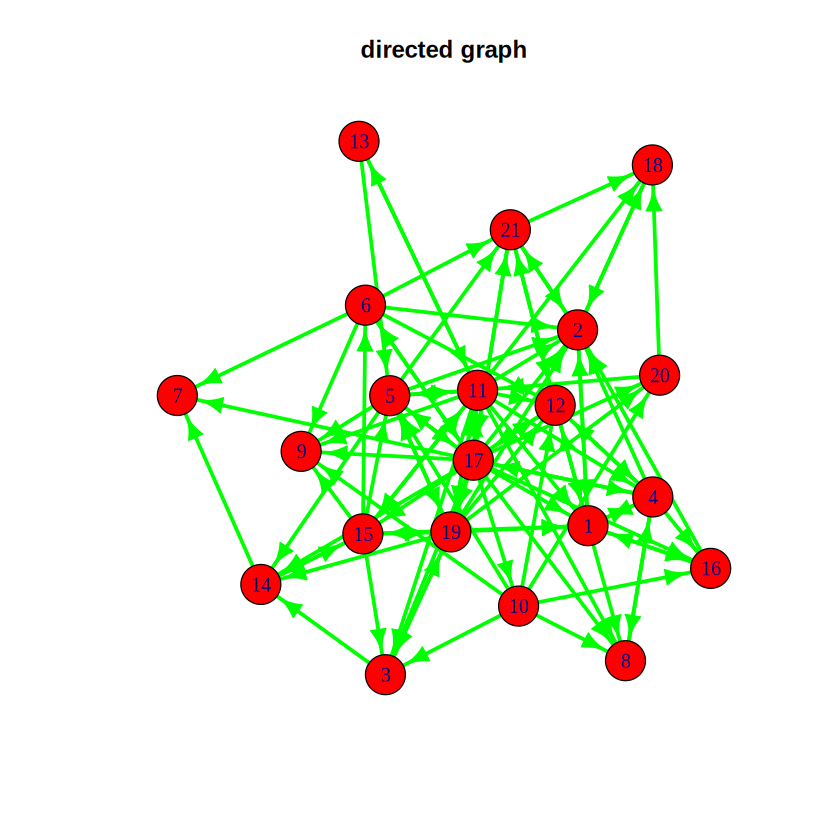

In [58]:
# п.4 изобразим граф
plot(
  graf2,                       # граф, которй строим
  main = "directed graph",     # название полученного изображения графа
  vertex.color = "red", vertex.shape = "circle",   # параметры вершин  (некоторые)
  edge.color = "green", edge.width = 3,            # параметры ребер   (некоторые)
  edge.arrow.size = 1, edge.arrow.width = 1        # параметры стрелок (некоторые)
)

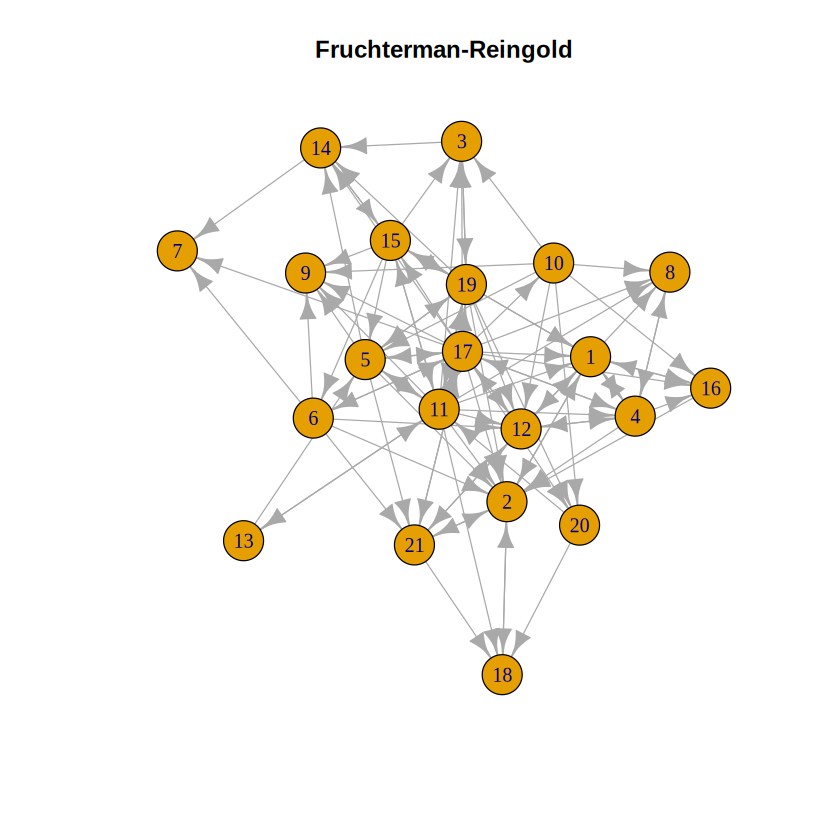

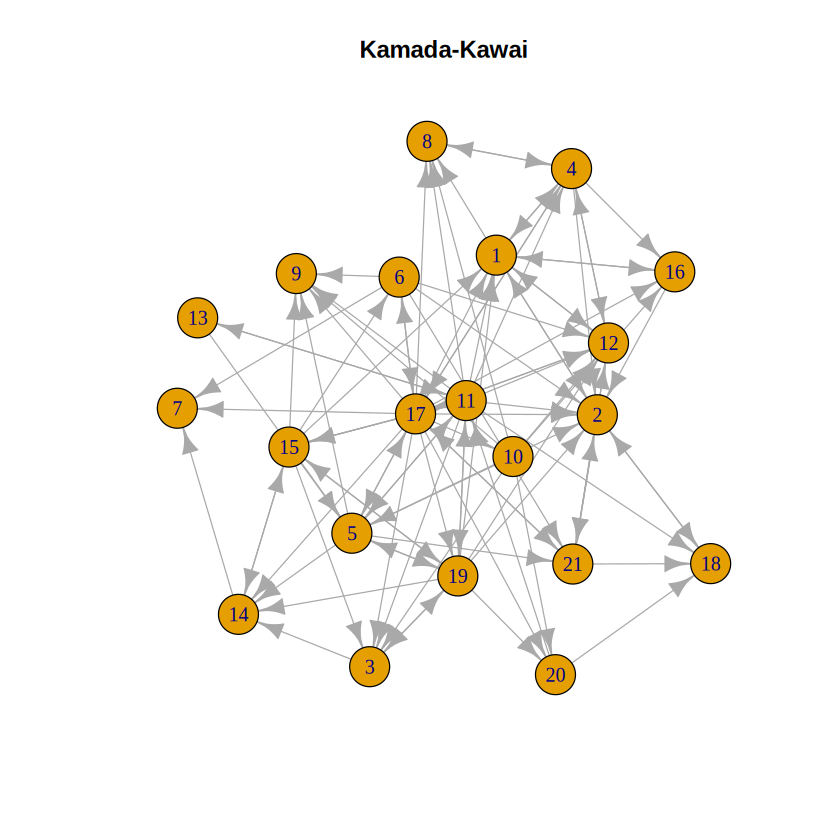

In [59]:
# п.5 изобразим граф, используя алгоритмы укладки Фрюхтермана-Рейнгольда и Камада-Каваи
plot(graf2, layout = layout_with_fr, main = "Fruchterman-Reingold")
plot(graf2, layout = layout_with_kk, main = "Kamada-Kawai")

In [60]:
# п.6 описательная сводка графа
# направленный, неименованный, невзвешенный, недвудольный, 21 вершина, 102 ребра
graf2

IGRAPH b173d39 D--- 21 102 -- 
+ edges from b173d39:
 [1]  1-> 2  1-> 4  1-> 8  1->12  1->16  2-> 1  2->18  2->21  3->14  3->19
[11]  4-> 1  4-> 2  4-> 8  4->12  4->16  4->17  5-> 2  5-> 9  5->11  5->14
[21]  5->17  5->19  5->21  6-> 2  6-> 7  6-> 9  6->12  6->17  6->21  8-> 4
[31] 10-> 3 10-> 5 10-> 8 10-> 9 10->12 10->16 10->20 11-> 1 11-> 2 11-> 3
[41] 11-> 4 11-> 5 11-> 8 11-> 9 11->12 11->13 11->15 11->17 11->18 11->19
[51] 12-> 1 12-> 4 12->17 12->21 13-> 5 13->11 14-> 7 14->15 15-> 1 15-> 3
[61] 15-> 5 15-> 6 15-> 9 15->11 15->14 15->19 16-> 1 16-> 2 17-> 1 17-> 2
[71] 17-> 3 17-> 4 17-> 5 17-> 6 17-> 7 17-> 8 17-> 9 17->10 17->11 17->12
[81] 17->14 17->15 17->16 17->19 17->20 17->21 18-> 2 19-> 1 19-> 2 19-> 3
+ ... omitted several edges

In [61]:
# п.7 пятичисловая сводка
# a. размер сети
vcount(graf2)
# b. плотность сети
edge_density(graf2, loops = FALSE)
# c. число компонент связности
count_components(graf2)
# d. диаметр сети
diameter(graf2, directed = TRUE, unconnected = TRUE)
# e. коэффициент кластеризации
transitivity(graf2, type = "global")

[1] 21

[1] 0.2428571

[1] 1

[1] 5

[1] 0.4714946

10. Заполнить таблицу для различных мер престижа. Сделать выводы.

Таблица заполнена аналогично таблице из п.8

| $n_{i}$ | $P'_{D}(n_{i})$ |$P'_{P}(n_{i})$ |$P'_{R}(n_{i})$ |
|:---:|:---:|:---:|:---:|
| 1 | 0.4 | 0.5785714 | 0.39231915 |
| 2 | 0.5 | 0.6 | 0.42552937 |
| 3 | 0.25 | 0.4263158 | 0.16144491 |
| 4 | 0.25 | 0.4764706 | 0.27194316 |
| 5 | 0.3 | 0.4378378 | 0.16834101 |
| 6 | 0.1 | 0.36 | 0.08089575 |
| 7 | 0.15 | 0.4011111 | 0.10194939 |
| 8 | 0.25 | 0.4764706 | 0.22611993 |
| 9 | 0.3 | 0.45125 | 0.17495152 |
| 10 | 0.05 | 0.324 | 0.04988790 |
| 11 | 0.3 | 0.4378378 | 0.17589765 |
| 12 | 0.4 | 0.54 | 0.32713825 |
| 13 | 0.05 | 0.3 | 0.03482824 |
| 14 | 0.25 | 0.4153846 | 0.18203729 |
| 15 | 0.2 | 0.405 | 0.15660303 |
| 16 | 0.2 | 0.4378378 | 0.19129169 |
| 17 | 0.3 | 0.4764706 | 0.25195542 |
| 18 | 0.2 | 0.4628571 | 0.18717284 |
| 19 | 0.25 | 0.4263158 | 0.18102254 |
| 20 | 0.15 | 0.3857143 | 0.09560883 |
| 21 | 0.25 | 0.4628571 | 0.24826784 |
|  |  |  |  |
| это | длиная строка | чтобы было | покрасивее |

In [70]:
install.packages("sna")
library(igraph)(sna)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘coda’, ‘statnet.common’, ‘network’


Loading required package: statnet.common


Attaching package: ‘statnet.common’


The following objects are masked from ‘package:base’:

    attr, order, replace


Loading required package: network


‘network’ 1.20.0 (2026-02-06), part of the Statnet Project
* ‘news(package="network")’ for changes since last version
* ‘citation("network")’ for citation information
* ‘https://statnet.org’ for help, support, and other information



Attaching package: ‘network’


The following objects are masked from ‘package:igraph’:

    %c%, %s%, add.edges, add.vertices, delete.edges, delete.vertices,
    get.edge.attribute, get.edges, get.vertex.attribute, is.bipartite,
    is.directed, list.edge.attributes, list.vertex.attributes,
    set.edge.attribute, set.vertex.attribute


sna: Tools for Social Network Analysis
Version 2.8 created on 2024-09-07.

In [119]:
# вычисляем нормализованный престиж по степени для всех вершин графа V(graf), параметр "in" учитывает только входящие связи
p_d <- igraph::degree(graf2, v = V(graf2), mode = "in", normalized = TRUE)
p_d

# вычиляем нормированный престиж по степени, используя другую библиотеку
p_d1 <- sna::prestige(mat2, cmode = "indegree") / 20
p_d1

# нормализованный престиж по близости
dist_matrix <- distances(graf2, v = V(graf2), to = V(graf2), mode = "out")
I_i <- colSums(dist_matrix > 0 & dist_matrix < Inf)
dist_matrix[dist_matrix == Inf] <- 0
sum_dist <- colSums(dist_matrix)
p_p <- I_i * I_i / (sum_dist * 20)
p_p

# нормализованный престиж по рангу
p_r1 <- sna::prestige(mat2, cmode = "eigenvector")
p_r1

# сгруппируем престиж в таблицу
prestige <- matrix(c(p_d, p_p, p_r1), nrow = 21, ncol = 3)
colnames(prestige) <- c("P'_D", "P_P", "P'_R")

prestige

[1] 0.40 0.50 0.25 0.25 0.30 0.10 0.15 0.25 0.30 0.05 0.30 0.40 0.05 0.25 0.20
[16] 0.20 0.30 0.20 0.25 0.15 0.25

[1] 0.40 0.50 0.25 0.25 0.30 0.10 0.15 0.25 0.30 0.05 0.30 0.40 0.05 0.25 0.20
[16] 0.20 0.30 0.20 0.25 0.15 0.25

[1] 0.5785714 0.6000000 0.4263158 0.4764706 0.4378378 0.3600000 0.4011111
 [8] 0.4764706 0.4512500 0.3240000 0.4378378 0.5400000 0.3000000 0.4153846
[15] 0.4050000 0.4378378 0.4764706 0.4628571 0.4263158 0.3857143 0.4628571

[1] 0.39231915 0.42552937 0.16144491 0.27194316 0.16834101 0.08089575
 [7] 0.10194939 0.22611993 0.17495152 0.04988790 0.17589765 0.32713825
[13] 0.03482824 0.18203729 0.15660303 0.19129169 0.25195542 0.18717284
[19] 0.18102254 0.09560883 0.24826784

P'_D,P_P,P'_R
0.40,0.5785714,0.39231915
0.50,0.6000000,0.42552937
0.25,0.4263158,0.16144491
0.25,0.4764706,0.27194316
0.30,0.4378378,0.16834101
0.10,0.3600000,0.08089575
0.15,0.4011111,0.10194939
0.25,0.4764706,0.22611993
0.30,0.4512500,0.17495152
0.05,0.3240000,0.04988790


## Выводы

При выполнении практической работы мной были изучены основные функции для работы с социльными сетями в языке R. Были проанализированы две сети, были посчитаны их основные характеристики, такие как пятичисловая сводка и меры центральности (для направленной сети) и меры престижа (для ненаправленной). Также эти сети были построены с ипользованием разны алгоритмов укладки.

Из-за отстутствия в бибилиотеке igraph функций для поискка центральности по информации и престижа по близости, они были реализованы дополнительно.